<a href="https://colab.research.google.com/github/joshuacvo/Joshua_INFO4670_Fall2026/blob/main/Logistic_Regression_Car_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load the dataset
df = pd.read_csv("car_purchase_data.csv")

# Preview the first five rows
display(df.head())

# Check the dataset's size and missing values
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


Dataset shape: (400, 5)

Missing values:
User ID      0
Gender       0
Age          0
Salary       0
Purchased    0
dtype: int64


### Step 2: Split features and target

In [3]:
# Features: information used to make predictions
X = df[['Age', 'Salary']]

# Target: the actual outcome we want to predict
y = df['Purchased']

print('X shape:', X.shape)
print('y distribution:\n', y.value_counts())

X shape: (400, 2)
y distribution:
 Purchased
0    257
1    143
Name: count, dtype: int64


### Step 3: Train/Test Split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=0,
    stratify=y
)

print('Train size:', X_train.shape[0])
print('Test size:', X_test.shape[0])

Train size: 320
Test size: 80


### Step 4: Feature Scaling

In [5]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print('Scaling complete.')
print('First five scaled training rows:\n', X_train[:5])


Scaling complete.
First five scaled training rows:
 [[-0.25808475 -0.33624928]
 [-0.82439644 -0.77364672]
 [ 1.06330919 -1.21104417]
 [-0.35247004 -0.77364672]
 [ 0.9689239   1.87989775]]


### Step 5: Train Logistic Regression Model

In [6]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print('Model trained.')

Model trained.


### Step 6: Predict and Evaluate

In [7]:
# Predict purchase outcomes for the test customers
y_pred = model.predict(X_test)

# Compare predictions with actual outcomes
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f'Accuracy: {acc:.2%}')
print('\nConfusion Matrix:\n', cm)
print('\nClassification Report:\n',
      classification_report(y_test, y_pred))

Accuracy: 81.25%

Confusion Matrix:
 [[47  4]
 [11 18]]

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.92      0.86        51
           1       0.82      0.62      0.71        29

    accuracy                           0.81        80
   macro avg       0.81      0.77      0.78        80
weighted avg       0.81      0.81      0.81        80



### Step 7: Visualization of Decision Regions

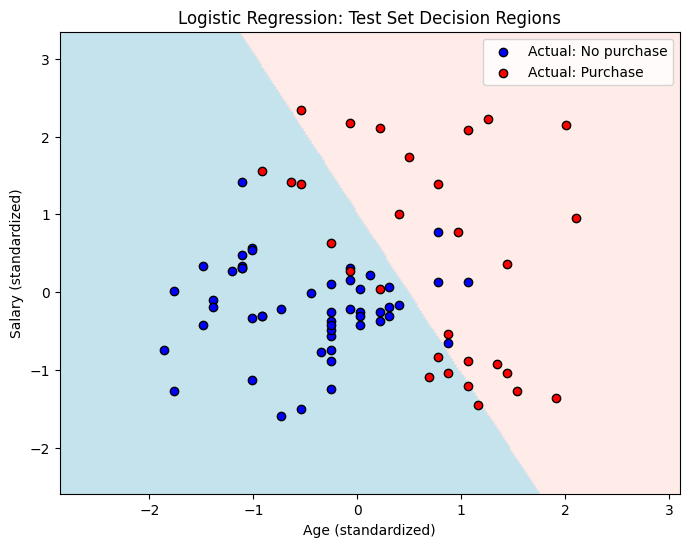

In [8]:
# Use standardized test features and actual outcomes
X_set = X_test
y_set = y_test.to_numpy()

# Create a grid covering the plotted age and salary ranges
age_grid, salary_grid = np.meshgrid(
    np.linspace(X_set[:, 0].min() - 1,
                X_set[:, 0].max() + 1, 300),
    np.linspace(X_set[:, 1].min() - 1,
                X_set[:, 1].max() + 1, 300)
)

# Predict a class for every point on the grid
grid_points = np.c_[age_grid.ravel(), salary_grid.ravel()]
predictions = model.predict(grid_points).reshape(age_grid.shape)

plt.figure(figsize=(8, 6))

# Background colors represent the model's predictions
plt.contourf(
    age_grid, salary_grid, predictions,
    levels=[-0.5, 0.5, 1.5],
    colors=['lightblue', 'mistyrose'],
    alpha=0.7
)

# Dots represent customers' actual outcomes
for label, color, name in [
    (0, 'blue', 'Actual: No purchase'),
    (1, 'red', 'Actual: Purchase')
]:
    plt.scatter(
        X_set[y_set == label, 0],
        X_set[y_set == label, 1],
        color=color,
        edgecolor='black',
        label=name
    )

plt.xlabel('Age (standardized)')
plt.ylabel('Salary (standardized)')
plt.title('Logistic Regression: Test Set Decision Regions')
plt.legend()
plt.show()


## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

Logistic regression estimates the probability that a customer belongs to a particular class. A decision threshold, typically 0.50, converts this probability into a classification. Probabilities above 0.50 are classified as a purchase (1), while probabilities below 0.50 are classified as no purchase (0). This allows the model to use probabilities to predict categorical outcomes.

The model assigns higher purchase probabilities to older customers and customers with higher salaries. Both features have positive coefficients, meaning that increasing either feature raises the predicted purchase probability when the other feature is held constant. Age has the larger standardized coefficient, indicating a stronger effect per standard-deviation increase in this fitted model. These relationships describe patterns learned from the dataset and do not guarantee an individual customer’s decision.

Age and salary alone cannot fully explain purchasing decisions. Other factors, such as a customer’s budget, current vehicle condition, and transportation needs, are missing. Additionally, logistic regression produces a straight decision boundary with these two inputs, which may not capture more complex patterns. The model achieved 81.25% accuracy, correctly classifying 65 of 80 test customers. It missed 11 actual purchasers and incorrectly predicted purchases for four non-purchasers, showing that identifying purchasers was its main weakness.

Additional features could include current vehicle age, household size, existing debt, purchase budget, and whether the customer needs a replacement vehicle. Preprocessing could include checking for missing values, duplicates, and unusual observations. Polynomial or interaction features could help logistic regression capture more complex relationships between age and salary. Cross-validation on the training data could help select model settings before evaluating the final model on the held-out test set. These changes could improve performance, but improvement would need to be verified.